# 24 · GPU back-end and the community model registry

**GPU.** `hf.backend.use("cupy")` moves the heavy kernels to an NVIDIA GPU:
- batched diagonalisation of whole k-point chunks;
- the Kubo/Berry-curvature kernels (AHC, SHC, OHC, Chern from curvature);
- KPM Chebyshev recursions (DOS, LDOS, Kubo-Bastin).

Results come back as NumPy arrays, so nothing else changes. Install CuPy matching your CUDA
(`pip install cupy-cuda12x`). `use("auto")` falls back to the CPU when no GPU is visible.

**Registry.** Every model in hopforge carries a **reference** and a **benchmark** that reproduces a published number.
`hf.models.validate(name)` checks a model; `register_model(...)` adds yours; packages can ship models as plugins.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hopforge as hf
M = hf.models
%matplotlib inline

## 1 · Choosing a back-end

In [2]:
print("available back-ends:", hf.backend.available())
import time
m = hf.models.kane_mele(lso=0.06)
for be in hf.backend.available():
    with hf.backend.on(be):
        t = time.time()
        r = hf.spin_hall(m, mu=0.0, nk=200)
        print(f"{be:6s}: sigma_SH = {r.sigma[0]:+.4f}   {time.time() - t:.2f} s")
with hf.backend.on("auto"):
    print("auto picked:", hf.backend.name())

available back-ends: ['numpy']


numpy : sigma_SH = -1.0000   0.27 s
auto picked: numpy


On a GPU node the same cell prints a `cupy` line too. Tips:
* Use large meshes (`nk` ≥ 300) or large KPM systems: the GPU wins once there is enough work per transfer.
* `n_jobs` is ignored on the GPU back-end, because CUDA cannot be shared with forked workers. One GPU typically replaces a 40-core node for these kernels.
* `hf.backend.xp()` returns the active array module if you write your own kernels.

```python
hf.backend.use("cupy")
sigma = hf.orbital_hall(model, mu=mus, nk=600)      # Kubo kernel on the GPU
E, rho = hf.kpm.dos(H_sparse, num_moments=2000, num_vectors=64)
hf.backend.use("numpy")
```

## 2 · The model registry: references and benchmarks

In [3]:
for name in ("haldane", "dice", "rhombohedral_graphene"):
    print(hf.models.info(name))
print(hf.models.validate("dice"))

{'name': 'haldane', 'dim': 2, 'description': 'Haldane Chern insulator', 'reference': 'Haldane, PRL 61, 2015 (1988)', 'benchmark': 'Haldane phase boundary', 'author': 'hopforge', 'tags': (), 'source': 'built-in'}
{'name': 'dice', 'dim': 2, 'description': 'alpha-T3 / dice lattice', 'reference': 'Sutherland, PRB 34, 5208 (1986); Raoux et al., PRL 112, 026402 (2014)', 'benchmark': '_chk_dice', 'author': 'hopforge', 'tags': (), 'source': 'built-in'}
{'name': 'rhombohedral_graphene', 'dim': 2, 'description': 'ABC N-layer graphene, E ~ k^N (Min & MacDonald 2008)', 'reference': 'Min & MacDonald, PRB 77, 155416 (2008)', 'benchmark': 'Chiral decomposition of ABC graphene', 'author': 'hopforge', 'tags': (), 'source': 'built-in'}
dice: PASS
  builds       ok
  dimension    ok
  hermitian    ok
  finite       ok
  reproducible ok
  reference    ok
  benchmark    ok
  benchmark    published flat band at E = 0  |  model 0.0


In [4]:
res = hf.models.validate_all(run_benchmark=False, verbose=False)     # structural checks of every model
print(sum(r.passed for r in res), "/", len(res), "models pass the structural checks")
for name in ("kagome", "pyrochlore", "altermagnet_dwave", "bdg_square"):
    v = hf.models.validate(name)
    print(f"{name:20s} {'PASS' if v.passed else 'FAIL'}   published {v.benchmark[0]}  |  model {v.benchmark[1]}")

36 / 36 models pass the structural checks
kagome               PASS   published 2.0  |  model 2.0
pyrochlore           PASS   published two flat bands at E = 2t  |  model (2.0, 2.0)
altermagnet_dwave    PASS   published split along G-X, degenerate along G-M  |  model (0.7394, 0.0)
bdg_square           PASS   published BCS gap Delta = 0.2 on the Fermi surface  |  model 0.2


## 3 · Register your own model, with its benchmark

The sawtooth (delta) chain with $t'=\sqrt2\,t$ has an exactly flat band at $E=2t$
(Huber & Altman, PRB 82, 184502 (2010)). The benchmark reproduces that number, and `validate` checks everything else.

sawtooth: PASS
  builds       ok
  dimension    ok
  hermitian    ok
  finite       ok
  reproducible ok
  reference    ok
  benchmark    ok
  benchmark    published 2.0  |  model 2.0


Text(0.5, 1.0, 'sawtooth chain: flat band at E = 2t')

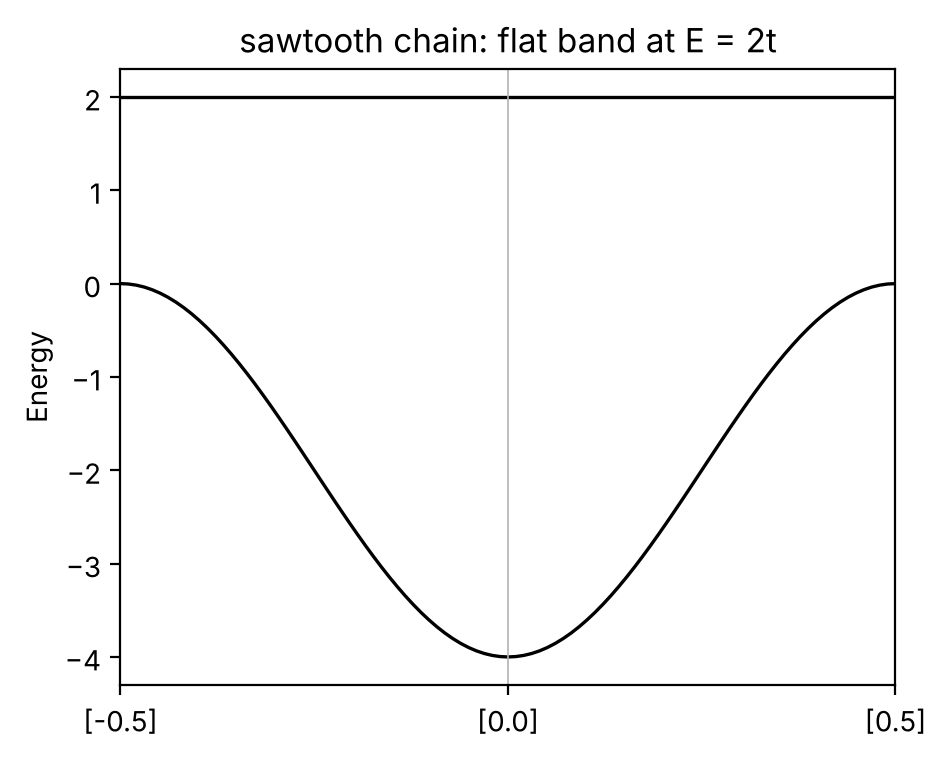

In [5]:
def _sawtooth_benchmark():
    m = sawtooth()
    E = m.energies(hf.kmesh(m, 64))[:, 1]
    return 2.0, round(float(E.mean()), 10), bool(np.ptp(E) < 1e-10 and abs(E.mean() - 2) < 1e-10)

@hf.models.register_model("sawtooth", dim=1, description="sawtooth (delta) chain, flat band for t' = sqrt(2) t",
                          reference="Huber & Altman, PRB 82, 184502 (2010)",
                          benchmark=_sawtooth_benchmark, author="tutorial 24", replace=True)
def sawtooth(t=1.0, tp=np.sqrt(2)):
    lat = hf.Lattice([[1.0]], [("A", [0]), ("B", [0.5])])
    m = hf.Model(lat, name="sawtooth chain")
    m.add_hopping(-t, "A", "A", [1])
    m.add_hopping(-tp, "A", "B", [0]); m.add_hopping(-tp, "B", "A", [1])
    return m

print(hf.models.validate("sawtooth"))
hf.plot_bands(hf.models.get("sawtooth"), hf.kpath(hf.models.get("sawtooth"), [[-0.5], [0], [0.5]], 100))
plt.title("sawtooth chain: flat band at E = 2t")

In [6]:
# community benchmarks run together with the built-in ones
res = hf.benchmarks.run(names=["[community] sawtooth"], verbose=True)

benchmark             pass  time   published  |  hopforge
[community] sawtooth  PASS    0.0s  2.0  |  2.0 

1/1 benchmarks reproduce the published results


## 4 · Ship models from your own package

```toml
# pyproject.toml of your package
[project.entry-points."hopforge.models"]
mymodels = "mypackage.hopforge_models"   # importing it calls hf.models.register_model(...)
```

After `pip install mypackage`, your models appear in `hf.models.list_models()`. `python -m hopforge.benchmarks` runs their benchmarks, and `hf.models.validate_all()` checks them in CI.
The `community/` folder of the repository has a complete example (`breathing_kagome.py`) and the contribution rules.

## Summary
* `hf.backend.use('cupy' | 'numpy' | 'auto')` switches the Kubo, k-mesh and KPM kernels to the GPU, with identical results.
* Every library model has a reference and a benchmark; `validate` / `validate_all` check them.
* `register_model(..., reference=, benchmark=)` and entry-point plugins make hopforge extensible without forking it.

---
## Quiz 24: GPU back-end and model registry

Twenty multiple-choice questions on this module. Run the next cell for a clickable
version (needs `ipywidgets`), or use the text version below it and grade yourself with
`quiz.check({1: 'a', 2: 'c', ...})`.

In [7]:
quiz = hf.Quiz(24)
quiz.interactive()

In [8]:
quiz.show()

=== Quiz 24: GPU back-end and the community model registry ===

Q1. `hf.backend.use('cupy')` moves to the GPU
   (a) the plotting
   (b) the quiz
   (c) k-mesh diagonalisation, Kubo kernels and KPM recursions
   (d) file I/O

Q2. `hf.backend.use('auto')` chooses
   (a) CuPy when a CUDA GPU is visible, otherwise NumPy
   (b) always NumPy
   (c) always CuPy
   (d) a random back-end

Q3. On the GPU back-end, n_jobs is ignored because
   (a) CUDA contexts cannot be shared with forked worker processes
   (b) numpy forbids it
   (c) GPUs are slow
   (d) it is a bug

Q4. When does the GPU pay off?
   (a) never
   (b) printing
   (c) tiny 2x2 models
   (d) large k-meshes or large sparse KPM systems with enough work per transfer

Q5. Which package provides the GPU arrays?
   (a) CuPy
   (b) pandas
   (c) sympy
   (d) matplotlib

Q6. Every model in the hopforge registry carries
   (a) nothing
   (b) a reference and a benchmark
   (c) a DFT input
   (d) a GUI

Q7. A registry benchmark is
   (a) a

In [9]:
my_answers = {
    1: '',
    2: '',
    3: '',
    4: '',
    5: '',
    6: '',
    7: '',
    8: '',
    9: '',
    10: '',
    11: '',
    12: '',
    13: '',
    14: '',
    15: '',
    16: '',
    17: '',
    18: '',
    19: '',
    20: '',
}
quiz.check(my_answers)

Q1: (no answer)
Q2: (no answer)
Q3: (no answer)
Q4: (no answer)
Q5: (no answer)
Q6: (no answer)
Q7: (no answer)
Q8: (no answer)
Q9: (no answer)
Q10: (no answer)
Q11: (no answer)
Q12: (no answer)
Q13: (no answer)
Q14: (no answer)
Q15: (no answer)
Q16: (no answer)
Q17: (no answer)
Q18: (no answer)
Q19: (no answer)
Q20: (no answer)

Score: 0 / 20


0